In [135]:
# 1. Import des bibliothèques
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import joblib

In [136]:
# 2. Chargement du datasets
df = pd.read_csv('Téléchargements/laptop_data.csv')
# Aperçu des données
print("Dimensions du dataset :", df.shape)
print("\n Aperçu des premières lignes :")
df.head()


Dimensions du dataset : (1303, 12)

 Aperçu des premières lignes :


,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [137]:
# 3. Valeurs manquantes
print("\n Valeurs manquantes par colonne :")
print(df.isnull().sum())
df.dropna(inplace=True)  # pour simplifier

# Si petites quantités → suppression ou remplissage
# Exemple : remplissage des valeurs manquantes dans 'Memory' par la valeur la plus fréquente
if df['Memory'].isnull().sum() > 0:
    df['Memory'].fillna(df['Memory'].mode()[0], inplace=True)


 Valeurs manquantes par colonne :
Unnamed: 0          0
Company             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price               0
dtype: int64


In [138]:
# Création de variables dérivées
df['Brand'] = df['Company']
df['Cpu Brand'] = df['Cpu'].apply(lambda x: x.split()[0])
df['Gpu Brand'] = df['Gpu'].apply(lambda x: x.split()[0])
df['Memory_Type'] = df['Memory'].apply(lambda x: 'SSD' if 'SSD' in x else ('HDD' if 'HDD' in x else 'Other'))
df['Ram'] = df['Ram'].astype(str).str.replace('GB', '').astype(int)
df['Weight'] = df['Weight'].astype(str).str.replace('kg', '').astype(float)

df['Touchscreen'] = df['ScreenResolution'].apply(lambda x: 1 if 'Touchscreen' in x else 0)
df['IPS'] = df['ScreenResolution'].apply(lambda x: 1 if 'IPS' in x else 0)
# Calcul du PPI
df['X_res'] = df['ScreenResolution'].str.extract(r'(\d+)x').astype(float)
df['Y_res'] = df['ScreenResolution'].str.extract(r'x(\d+)').astype(float)
df['ppi'] = ((df['X_res']**2 + df['Y_res']**2)**0.5) / df['Inches']



In [139]:

# . Nettoyage des anomalies sur la variable cible 'Price'
print("\n Statistiques sur les prix :")
print(df['Price'].describe())

# Exemple : suppression des ordinateurs à moins de 100$ (anomalie probable)
df = df[df['Price'] >= 100]
# Sélection finale des colonnes
df_model = df[['Brand', 'Ram', 'Weight', 'Touchscreen', 'IPS', 'ppi',
               'Cpu Brand', 'Gpu Brand', 'Memory_Type', 'Price']]





 Statistiques sur les prix :
count      1303.000000
mean      59870.042910
std       37243.201786
min        9270.720000
25%       31914.720000
50%       52054.560000
75%       79274.246400
max      324954.720000
Name: Price, dtype: float64


In [150]:

df_model = df.copy()
encoders = {}  # Dictionnaire pour stocker les encodeurs

# Encodage des colonnes catégorielles et sauvegarde des correspondances
for col in df_model.columns:
    if df_model[col].dtype == 'object':
        le = LabelEncoder()
        df_model[col] = le.fit_transform(df_model[col])
        encoders[col] = le  # Stocke l'encodeur pour chaque colonne

# Sauvegarde du dictionnaire d'encodeurs
scaler = StandardScaler()
scaler.fit(X)
joblib.dump(scaler, "~/Documents/Prévision_Prix_Ordinateur/scaler.pkl")

# ➕ Affichage des correspondances texte <-> code numérique
print("\n✅ Correspondances Label Encoding :")
for col, le in encoders.items():
    print(f"\nColonne : {col}")
    for i, class_ in enumerate(le.classes_):
        print(f"{i} => {class_}")


FileNotFoundError: [Errno 2] No such file or directory: '~/Documents/Prévision_Prix_Ordinateur/scaler.pkl'

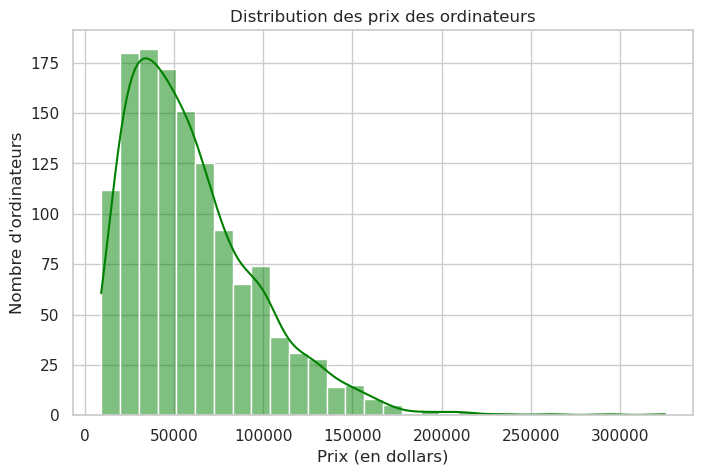

In [141]:
# Visualisation des données
# Style graphique plus propre
sns.set(style="whitegrid", palette="muted")

# 📍 2. Distribution du prix
plt.figure(figsize=(8, 5))
sns.histplot(df['Price'], kde=True, bins=30, color='green')
plt.title("Distribution des prix des ordinateurs")
plt.xlabel("Prix (en dollars)")
plt.ylabel("Nombre d'ordinateurs")
plt.show()

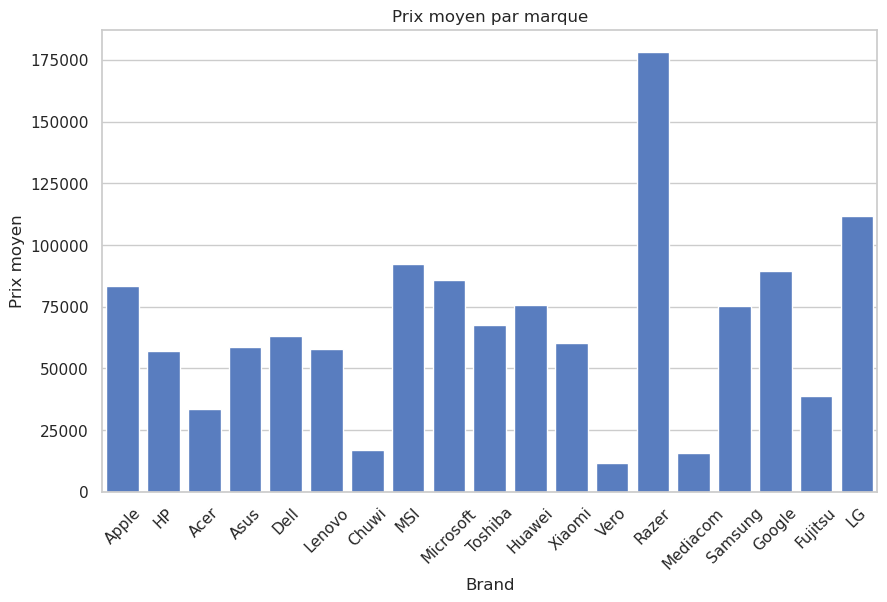

In [142]:
# 📍 3. Prix moyen par marque
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='Brand', y='Price', errorbar=None)
plt.title("Prix moyen par marque")
plt.xticks(rotation=45)
plt.ylabel("Prix moyen")
plt.show()

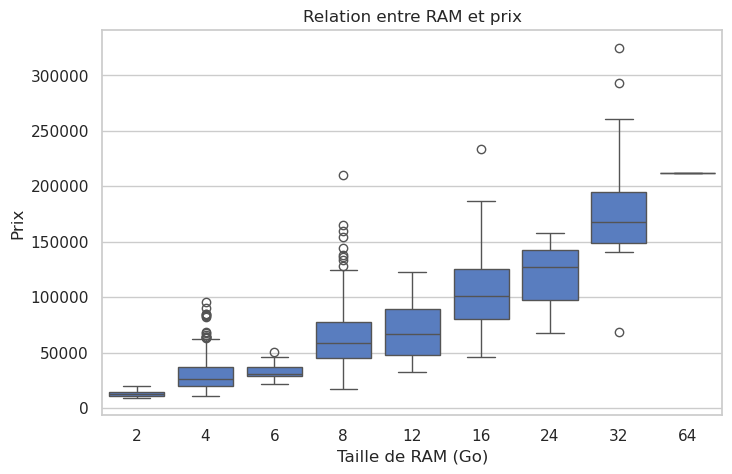

In [143]:
# 📍 4. Impact de la RAM sur le prix
plt.figure(figsize=(8, 5))
sns.boxplot(x='Ram', y='Price', data=df)
plt.title("Relation entre RAM et prix")
plt.xlabel("Taille de RAM (Go)")
plt.ylabel("Prix")
plt.show()

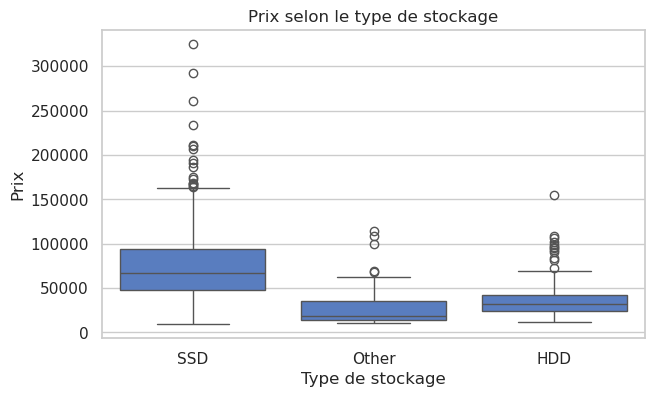

In [144]:
# 📍 5. Prix moyen selon le type de mémoire
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='Memory_Type', y='Price')
plt.title("Prix selon le type de stockage")
plt.xlabel("Type de stockage")
plt.ylabel("Prix")
plt.show()


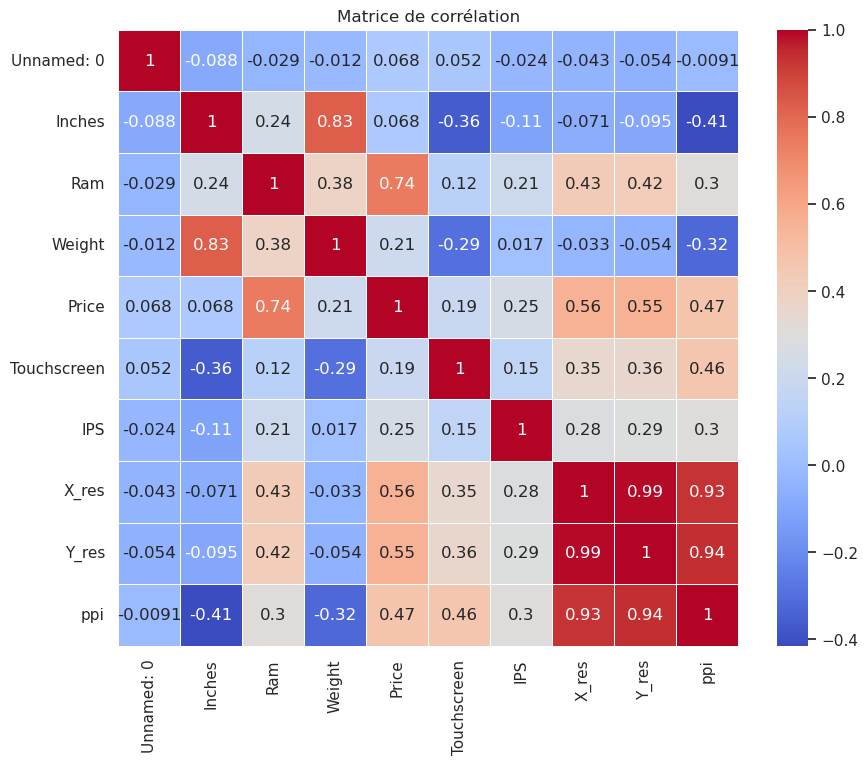

In [145]:
# 📍 6. Corrélation entre variables numériques
plt.figure(figsize=(10, 8))
numerical_features = df.select_dtypes(include=['int64', 'float64'])
correlation_matrix = numerical_features.corr()

sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", linewidths=0.5)
plt.title("Matrice de corrélation")
plt.show()


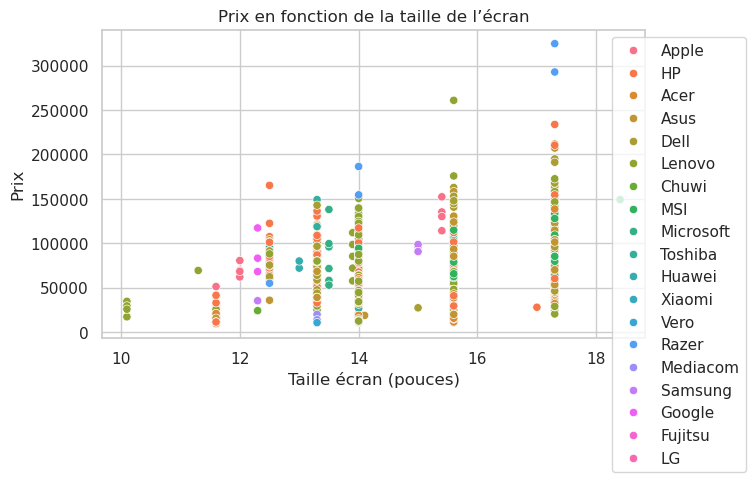

In [146]:
# 📍 7. Scatter plot : Taille écran vs Prix
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x='Inches', y='Price', hue='Brand')
plt.title("Prix en fonction de la taille de l’écran")
plt.xlabel("Taille écran (pouces)")
plt.ylabel("Prix")
plt.legend(loc='upper right', bbox_to_anchor=(1.2, 1))
plt.show()

In [147]:

if 'Unnamed: 0' in df_model.columns:
    df_model = df_model.drop(columns=['Unnamed: 0'])

X = df_model.drop('Price', axis=1)
y = df_model['Price']



# Afficher les colonnes utilisées pour l'entraînement

print("Liste exacte des colonnes utilisées pour l'entraînement :")
print(X.columns.tolist())
# Séparation en jeu d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Entraînement du modèle
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)




Liste exacte des colonnes utilisées pour l'entraînement :
['Company', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Brand', 'Cpu Brand', 'Gpu Brand', 'Memory_Type', 'Touchscreen', 'IPS', 'X_res', 'Y_res', 'ppi']


RandomForestRegressor(random_state=42)

In [148]:
#Evaluation
# 7. Évaluation des modèles
def eval_model(name, y_true, y_pred):
    print(f"\n Évaluation du modèle : {name}")
    print("MAE :", mean_absolute_error(y_true, y_pred))
    print("RMSE :", np.sqrt(mean_squared_error(y_true, y_pred)))
    print("R² :", r2_score(y_true, y_pred))

eval_model("Régression linéaire", y_test, y_pred_lr)
eval_model("Random Forest", y_test, y_pred_rf)

# 8. Validation croisée

print("\n Validation croisée sur 5 folds (RandomForest)...")
cv_scores = cross_val_score(rf_model, X, y, cv=5, scoring='r2')
print("Scores R² :", cv_scores)
print("R² moyen :", cv_scores.mean())


 Évaluation du modèle : Régression linéaire
MAE : 14069.750282707553
RMSE : 22147.616145012737
R² : 0.6598075660984988

 Évaluation du modèle : Random Forest
MAE : 9652.406978206898
RMSE : 16173.696849199598
R² : 0.8185782833434645

 Validation croisée sur 5 folds (RandomForest)...
Scores R² : [0.8293278  0.82050247 0.83688424 0.77900676 0.76544536]
R² moyen : 0.8062333259026154


In [149]:

# Sauvegarder le modèle RandomForest entraîné

joblib.dump(model, "laptop_price_model.pkl")
joblib.dump(encoders, "encoders.pkl")
joblib.dump(scaler, "scaler.pkl")



['scaler.pkl']